# Tutorial 8 Tasks: Faster R-CNN in PyTorch


## Step 0: Imports

In [1]:
import os, glob, random, time
import xml.etree.ElementTree as ET
import numpy as np, cv2
import matplotlib.pyplot as plt, matplotlib.patches as patches
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator
from torchvision.ops import MultiScaleRoIAlign

random.seed(0); np.random.seed(0); torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## Step 1: Data



train 150 | val 50 | classes ['square', 'circle', 'triangle']


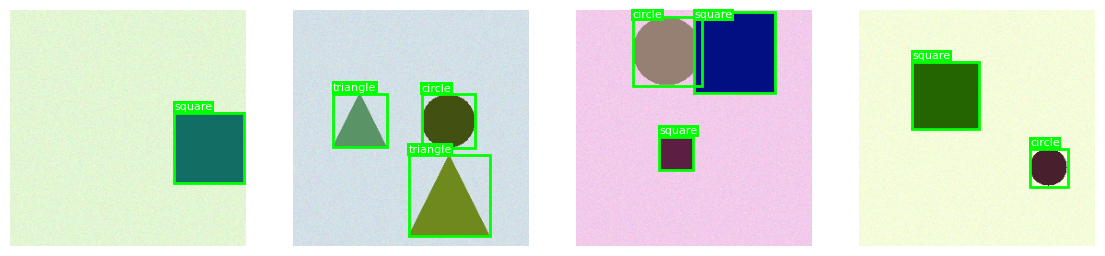

In [2]:
USE_CUSTOM_DATA = False            # True = use your own labelled images
DATA_DIR = "/content/my_data"      # folder with images + .xml files

# ---------- helper: IoU ----------
def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0

# ---------- demo dataset ----------
def make_sample(rng, size=256):
    img = np.clip(rng.integers(200, 256, (1,1,3)) + rng.normal(0, 6, (size,size,3)), 0, 255).astype(np.uint8).copy()
    boxes, labels = [], []
    for _ in range(int(rng.integers(1, 5))):
        s = int(rng.integers(32, 90)); x, y = int(rng.integers(0, size-s)), int(rng.integers(0, size-s))
        box = [x, y, x+s, y+s]
        if any(iou(box, b) > 0.05 for b in boxes): continue
        lab = int(rng.integers(1, 4)); col = tuple(int(v) for v in rng.integers(0, 160, 3))
        if lab == 1:   cv2.rectangle(img, (x, y), (x+s, y+s), col, -1)
        elif lab == 2: cv2.circle(img, (x+s//2, y+s//2), s//2, col, -1)
        else:          cv2.fillPoly(img, [np.array([[x+s//2, y], [x, y+s], [x+s, y+s]], np.int32)], col)
        boxes.append(box); labels.append(lab)
    return img, np.array(boxes, np.float32), np.array(labels, np.int64)

class ShapesDataset(Dataset):
    def __init__(self, n, seed):
        rng = np.random.default_rng(seed); self.data = [make_sample(rng) for _ in range(n)]
    def __len__(self): return len(self.data)
    def __getitem__(self, i):
        img, b, l = self.data[i]
        return torch.from_numpy(img).permute(2,0,1).float()/255, {"boxes": torch.from_numpy(b), "labels": torch.from_numpy(l)}

# ---------- your own data (Pascal VOC XML) ----------
def load_voc(root):
    samples, names = [], set()
    for xp in sorted(glob.glob(os.path.join(root, "**", "*.xml"), recursive=True)):
        r = ET.parse(xp).getroot(); folder = os.path.dirname(xp)
        path = os.path.join(folder, r.findtext("filename"))
        if not os.path.exists(path):
            stem = os.path.splitext(os.path.basename(xp))[0]
            found = [p for p in glob.glob(os.path.join(folder, stem + ".*")) if not p.endswith(".xml")]
            if not found: continue
            path = found[0]
        boxes, labs = [], []
        for o in r.findall("object"):
            bb = o.find("bndbox"); b = [float(bb.findtext(k)) for k in ("xmin","ymin","xmax","ymax")]
            if b[2] > b[0] and b[3] > b[1]: boxes.append(b); labs.append(o.findtext("name").strip())
        if boxes: samples.append((path, np.array(boxes, np.float32), labs)); names.update(labs)
    return samples, sorted(names)

class VOCDataset(Dataset):
    def __init__(self, samples, classes): self.s, self.c = samples, {n: i+1 for i, n in enumerate(classes)}
    def __len__(self): return len(self.s)
    def __getitem__(self, i):
        p, b, l = self.s[i]; img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
        return torch.from_numpy(img).permute(2,0,1).float()/255, {"boxes": torch.from_numpy(b), "labels": torch.tensor([self.c[n] for n in l])}

# ---------- build train / val ----------
if USE_CUSTOM_DATA:
    samples, CLASS_NAMES = load_voc(DATA_DIR); random.shuffle(samples)
    nv = max(1, len(samples)//5)
    train_ds, val_ds = VOCDataset(samples[nv:], CLASS_NAMES), VOCDataset(samples[:nv], CLASS_NAMES)
    MIN_SIZE, MAX_SIZE, ANCHORS = 480, 640, (32, 64, 128, 256)   # change anchors to match your object sizes
else:
    CLASS_NAMES = ["square", "circle", "triangle"]
    train_ds, val_ds = ShapesDataset(150, 1), ShapesDataset(50, 2)
    MIN_SIZE, MAX_SIZE, ANCHORS = 256, 256, (32, 64, 128)

NUM_CLASSES = len(CLASS_NAMES) + 1          # + background
collate = lambda b: tuple(zip(*b))
train_loader = DataLoader(train_ds, batch_size=8, shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(val_ds,   batch_size=8, shuffle=False, collate_fn=collate)
print(f"train {len(train_ds)} | val {len(val_ds)} | classes {CLASS_NAMES}")

# ---------- drawing helper ----------
def draw(ax, img, boxes, labels, scores=None, color=None, title=""):
    ax.imshow(img.permute(1,2,0).numpy())
    for i, (b, l) in enumerate(zip(boxes, labels)):
        c = color or "red"
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, edgecolor=c, linewidth=2))
        t = CLASS_NAMES[int(l)-1] + (f" {float(scores[i]):.2f}" if scores is not None else "")
        ax.text(b[0], max(b[1]-3, 8), t, color="white", fontsize=8, bbox=dict(facecolor=c, pad=1, edgecolor="none"))
    ax.set_title(title); ax.axis("off")

fig, axs = plt.subplots(1, 4, figsize=(14, 4))
for ax, i in zip(axs, random.sample(range(len(train_ds)), 4)):
    im, t = train_ds[i]; draw(ax, im, t["boxes"], t["labels"], color="lime")
plt.show()

## Step 2: Model



In [3]:
class Backbone(nn.Module):
    def __init__(self, channels=(64, 128, 256, 512)):
        super().__init__()
        layers, prev = [], 3
        for i, c in enumerate(channels):
            layers += [nn.Conv2d(prev, c, 3, padding=1), nn.BatchNorm2d(c), nn.ReLU(True)]
            if i < len(channels) - 1: layers.append(nn.MaxPool2d(2))
            prev = c
        self.body = nn.Sequential(*layers); self.out_channels = prev
    def forward(self, x): return self.body(x)

def build_model(channels=(64, 128, 256, 512)):
    return FasterRCNN(
        Backbone(channels), num_classes=NUM_CLASSES,
        rpn_anchor_generator=AnchorGenerator(sizes=(ANCHORS,), aspect_ratios=((0.5, 1.0, 2.0),)),
        box_roi_pool=MultiScaleRoIAlign(["0"], output_size=7, sampling_ratio=2),
        min_size=MIN_SIZE, max_size=MAX_SIZE, box_score_thresh=0.05).to(device)

model = build_model()
print("parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

parameters: 30,697,025


## Step 3: Train + evaluate (IoU → precision/recall → mAP)



In [4]:
def calc_map(preds, gts, num_classes, thr=0.5):
    aps = {}
    for c in range(1, num_classes):
        dets, gtb, n_gt = [], [], 0
        for i, (p, g) in enumerate(zip(preds, gts)):
            gtb.append(g["boxes"][g["labels"] == c]); n_gt += len(gtb[-1])
            for b, s in zip(p["boxes"][p["labels"] == c], p["scores"][p["labels"] == c]): dets.append((s, i, b))
        if n_gt == 0: continue
        dets.sort(key=lambda d: -d[0]); used = [np.zeros(len(g), bool) for g in gtb]; tp = np.zeros(len(dets))
        for k, (s, i, b) in enumerate(dets):
            if len(gtb[i]):
                ious = [iou(b, g) for g in gtb[i]]; j = int(np.argmax(ious))
                if ious[j] >= thr and not used[i][j]: tp[k] = 1; used[i][j] = True
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
        rec, prec = ctp / n_gt, ctp / np.maximum(ctp + cfp, 1e-9)
        mrec, mpre = np.r_[0, rec, 1], np.r_[0, prec, 0]
        for i in range(len(mpre) - 2, -1, -1): mpre[i] = max(mpre[i], mpre[i+1])
        idx = np.where(mrec[1:] != mrec[:-1])[0]
        aps[c] = float(np.sum((mrec[idx+1] - mrec[idx]) * mpre[idx+1]))
    return (float(np.mean(list(aps.values()))) if aps else 0.0), aps

@torch.no_grad()
def predict(model, loader):
    model.eval(); preds, gts = [], []
    for imgs, tg in loader:
        for o, t in zip(model([i.to(device) for i in imgs]), tg):
            preds.append({k: v.cpu().numpy() for k, v in o.items()})
            gts.append({k: v.numpy() for k, v in t.items()})
    return preds, gts

def train(model, epochs=30, lr=1e-3, eval_every=5):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    losses, maps = [], []
    for ep in range(1, epochs + 1):
        model.train(); total = 0
        for imgs, tg in train_loader:
            loss = sum(model([i.to(device) for i in imgs], [{k: v.to(device) for k, v in t.items()} for t in tg]).values())
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 10); opt.step(); total += loss.item()
        sched.step(); losses.append(total / len(train_loader)); msg = f"epoch {ep}/{epochs}  loss {losses[-1]:.3f}"
        if ep % eval_every == 0 or ep == epochs:
            m, _ = calc_map(*predict(model, val_loader), NUM_CLASSES); maps.append((ep, m)); msg += f"  val mAP@0.5 {m:.3f}"
        print(msg)
    return losses, maps

losses, maps = train(model, epochs=30)

epoch 1/30  loss 0.831
epoch 2/30  loss 0.471
epoch 3/30  loss 0.326
epoch 4/30  loss 0.224
epoch 5/30  loss 0.210  val mAP@0.5 0.915
epoch 6/30  loss 0.194
epoch 7/30  loss 0.166
epoch 8/30  loss 0.143
epoch 9/30  loss 0.131
epoch 10/30  loss 0.099  val mAP@0.5 1.000
epoch 11/30  loss 0.083
epoch 12/30  loss 0.078
epoch 13/30  loss 0.075
epoch 14/30  loss 0.067
epoch 15/30  loss 0.059  val mAP@0.5 1.000
epoch 16/30  loss 0.056
epoch 17/30  loss 0.055
epoch 18/30  loss 0.047
epoch 19/30  loss 0.044
epoch 20/30  loss 0.044  val mAP@0.5 1.000
epoch 21/30  loss 0.040
epoch 22/30  loss 0.038
epoch 23/30  loss 0.036
epoch 24/30  loss 0.035
epoch 25/30  loss 0.033  val mAP@0.5 1.000
epoch 26/30  loss 0.032
epoch 27/30  loss 0.032
epoch 28/30  loss 0.030
epoch 29/30  loss 0.031
epoch 30/30  loss 0.030  val mAP@0.5 1.000


### Results:

mAP@0.5 = 1.000
  AP     square: 1.000
  AP     circle: 1.000
  AP   triangle: 1.000


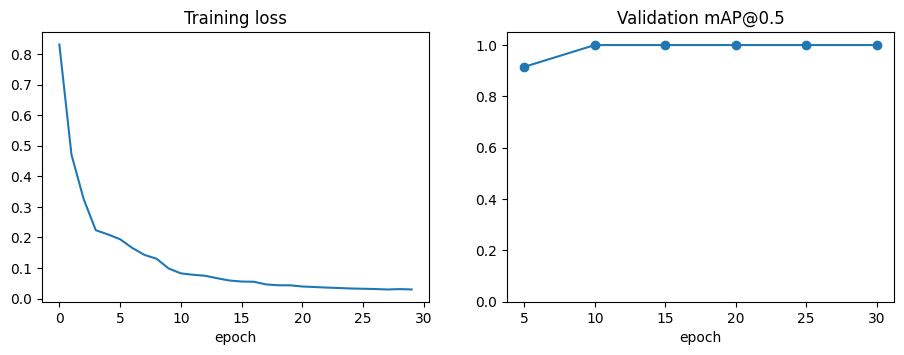

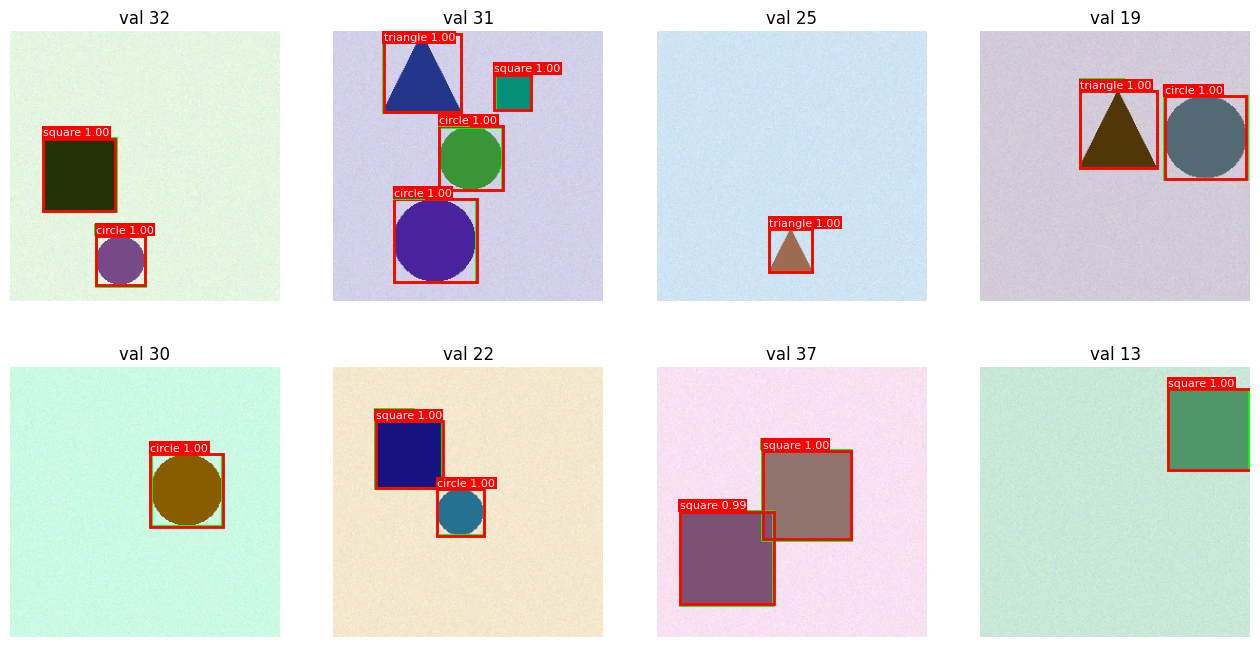

In [5]:
preds, gts = predict(model, val_loader)
mAP, per_class = calc_map(preds, gts, NUM_CLASSES)
print(f"mAP@0.5 = {mAP:.3f}")
for c, ap in per_class.items(): print(f"  AP {CLASS_NAMES[c-1]:>10}: {ap:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(losses); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(*zip(*maps), marker="o"); ax[1].set_title("Validation mAP@0.5"); ax[1].set_xlabel("epoch"); ax[1].set_ylim(0, 1.05)
plt.show()

fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, i in zip(axs.ravel(), random.sample(range(len(val_ds)), min(8, len(val_ds)))):
    im, t = val_ds[i]; keep = preds[i]["scores"] >= 0.5
    draw(ax, im, t["boxes"], t["labels"], color="lime")
    draw(ax, im, preds[i]["boxes"][keep], preds[i]["labels"][keep], preds[i]["scores"][keep], title=f"val {i}")
plt.show()

## Step 5 (Task 1): Change the number of layers




== 3 layers (64, 128, 256)
epoch 1/15  loss 1.068
epoch 2/15  loss 0.539
epoch 3/15  loss 0.402
epoch 4/15  loss 0.361
epoch 5/15  loss 0.326
epoch 6/15  loss 0.296
epoch 7/15  loss 0.262
epoch 8/15  loss 0.237
epoch 9/15  loss 0.207
epoch 10/15  loss 0.192
epoch 11/15  loss 0.179
epoch 12/15  loss 0.172
epoch 13/15  loss 0.164
epoch 14/15  loss 0.157
epoch 15/15  loss 0.153  val mAP@0.5 0.994

== 4 layers (64, 128, 256, 512)
epoch 1/15  loss 0.831
epoch 2/15  loss 0.440
epoch 3/15  loss 0.297
epoch 4/15  loss 0.234
epoch 5/15  loss 0.209
epoch 6/15  loss 0.180
epoch 7/15  loss 0.152
epoch 8/15  loss 0.136
epoch 9/15  loss 0.126
epoch 10/15  loss 0.108
epoch 11/15  loss 0.091
epoch 12/15  loss 0.079
epoch 13/15  loss 0.073
epoch 14/15  loss 0.070
epoch 15/15  loss 0.067  val mAP@0.5 1.000

== 5 layers (64, 128, 256, 512, 512)
epoch 1/15  loss 0.578
epoch 2/15  loss 0.303
epoch 3/15  loss 0.197
epoch 4/15  loss 0.155
epoch 5/15  loss 0.119
epoch 6/15  loss 0.132
epoch 7/15  loss 0.109


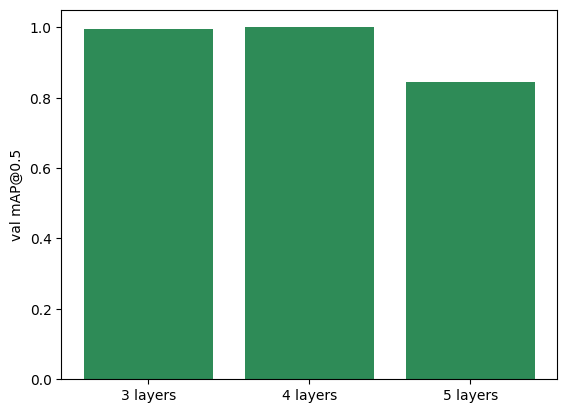

In [6]:
configs = {"3 layers": (64, 128, 256),
           "4 layers": (64, 128, 256, 512),
           "5 layers": (64, 128, 256, 512, 512)}
res = {}
for name, ch in configs.items():
    torch.manual_seed(0); m = build_model(ch)
    print("\n==", name, ch)
    _, mp = train(m, epochs=15, eval_every=15)
    res[name] = (sum(p.numel() for p in m.parameters()) / 1e6, mp[-1][1])

print("\nlayers      params(M)   mAP@0.5")
for k, (p, m) in res.items(): print(f"{k:<10}  {p:8.2f}   {m:.3f}")
plt.bar(res.keys(), [v[1] for v in res.values()], color="seagreen"); plt.ylabel("val mAP@0.5"); plt.ylim(0, 1.05); plt.show()

## Step 6 (Task 2): Take a data if you have and just randomly test it what it shows



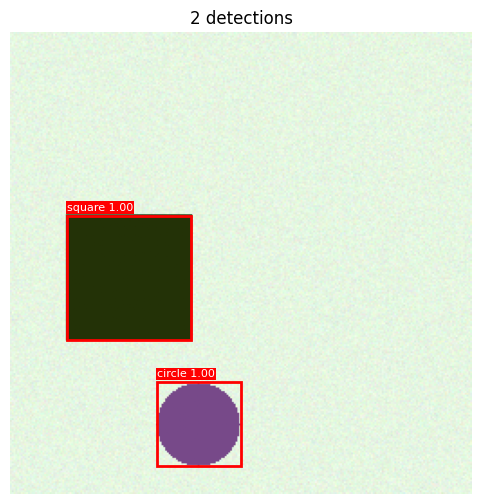

In [7]:
def test_image(path, thr=0.5):
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    t = torch.from_numpy(img).permute(2,0,1).float() / 255
    model.eval()
    with torch.no_grad(): o = model([t.to(device)])[0]
    k = (o["scores"] >= thr).cpu()
    fig, ax = plt.subplots(figsize=(6, 6))
    draw(ax, t, o["boxes"].cpu()[k], o["labels"].cpu()[k], o["scores"].cpu()[k], title=f"{k.sum().item()} detections")
    plt.show()


im, _ = val_ds[random.randrange(len(val_ds))]
cv2.imwrite("random_test.png", cv2.cvtColor((im.permute(1,2,0).numpy()*255).astype(np.uint8), cv2.COLOR_RGB2BGR))
test_image("random_test.png", thr=0.3)